In [1]:
# COGNIFYZ TECHNOLOGIES
# MACHINE LEARNING TASK 2
# RESTAURANT RECOMMENDATION SYSTEM

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

print("Restaurant Recommendation System")
print("Libraries imported successfully!")

Restaurant Recommendation System
Libraries imported successfully!


In [2]:
# STEP 2: LOAD THE ZOMATO DATASET

import os

print("Current folder:", os.getcwd())

possible_paths = [
    "../Dataset/zomato.csv",
    "Dataset/zomato.csv"
]

dataset_path = next(
    (path for path in possible_paths if os.path.exists(path)),
    None
)

if dataset_path is None:
    print("Dataset not found. Please check the project folder.")
else:
    df = pd.read_csv(dataset_path)

    print("Dataset loaded successfully!")
    print("Dataset Shape:", df.shape)

    display(df.head(10))

Current folder: C:\Users\Bhumiti\OneDrive\Desktop\Cognifyz_ML_Task2
Dataset loaded successfully!
Dataset Shape: (1000, 9)


,Restaurant ID,City,Cuisines,Votes,Average Cost for two,Price range,Has Online delivery,Has Table booking,Aggregate rating
0,100001,New Delhi,Desserts,2195,1500,3,No,No,2.7
1,100002,Chennai,Continental,156,1200,2,Yes,No,2.4
2,100003,Hyderabad,Cafe,994,2500,4,No,Yes,4.2
3,100004,Bengaluru,Desserts,1146,2500,4,No,No,4.5
4,100005,Bengaluru,Chinese,1994,1200,2,Yes,Yes,2.9
5,100006,Kolkata,Street Food,323,600,1,No,No,2.1
6,100007,New Delhi,Desserts,1085,1000,2,Yes,No,2.0
7,100008,Hyderabad,Cafe,381,600,1,Yes,Yes,2.7
8,100009,Noida,Continental,1969,1000,2,Yes,Yes,2.9
9,100010,New Delhi,Cafe,1581,1500,3,No,No,2.8


In [3]:
# STEP 3: DATA CLEANING AND PREPROCESSING

df = df.drop_duplicates().copy()

df["City"] = df["City"].astype(str).str.strip()
df["Cuisines"] = df["Cuisines"].astype(str).str.strip()

numeric_columns = [
    "Average Cost for two",
    "Price range",
    "Aggregate rating",
    "Votes"
]

for col in numeric_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df = df.dropna(
    subset=[
        "City",
        "Cuisines",
        "Average Cost for two",
        "Price range",
        "Aggregate rating"
    ]
).copy()

df["Votes"] = df["Votes"].fillna(0)

print("Data cleaning completed!")
print("Cleaned dataset shape:", df.shape)

display(df.head())
print("\nMissing values:")
display(df.isnull().sum())

Data cleaning completed!
Cleaned dataset shape: (1000, 9)


,Restaurant ID,City,Cuisines,Votes,Average Cost for two,Price range,Has Online delivery,Has Table booking,Aggregate rating
0,100001,New Delhi,Desserts,2195,1500,3,No,No,2.7
1,100002,Chennai,Continental,156,1200,2,Yes,No,2.4
2,100003,Hyderabad,Cafe,994,2500,4,No,Yes,4.2
3,100004,Bengaluru,Desserts,1146,2500,4,No,No,4.5
4,100005,Bengaluru,Chinese,1994,1200,2,Yes,Yes,2.9



Missing values:


Restaurant ID           0
City                    0
Cuisines                0
Votes                   0
Average Cost for two    0
Price range             0
Has Online delivery     0
Has Table booking       0
Aggregate rating        0
dtype: int64

In [4]:
# STEP 4: EXPLORATORY DATA ANALYSIS

print("Total Restaurants:", len(df))
print("Total Cities:", df["City"].nunique())
print("Total Cuisines:", df["Cuisines"].nunique())

print("\nTop 10 Popular Cuisines:")
display(df["Cuisines"].value_counts().head(10))

print("\nAverage Restaurant Rating:")
print(df["Aggregate rating"].mean())

Total Restaurants: 1000
Total Cities: 10
Total Cuisines: 10

Top 10 Popular Cuisines:


Cuisines
Chinese         105
Desserts        103
Cafe            103
Italian         103
Continental     101
Street Food     101
North Indian    101
Fast Food       100
South Indian     98
Mexican          85
Name: count, dtype: int64


Average Restaurant Rating:
2.926


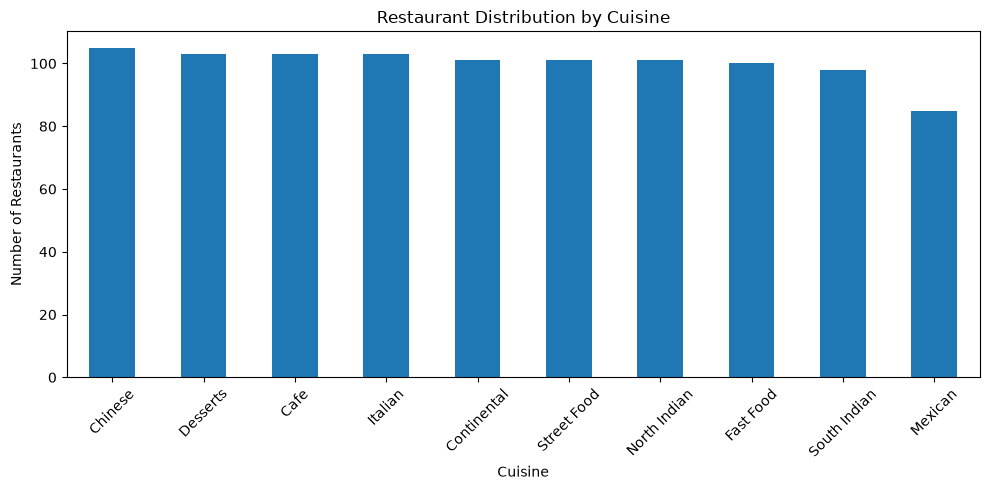

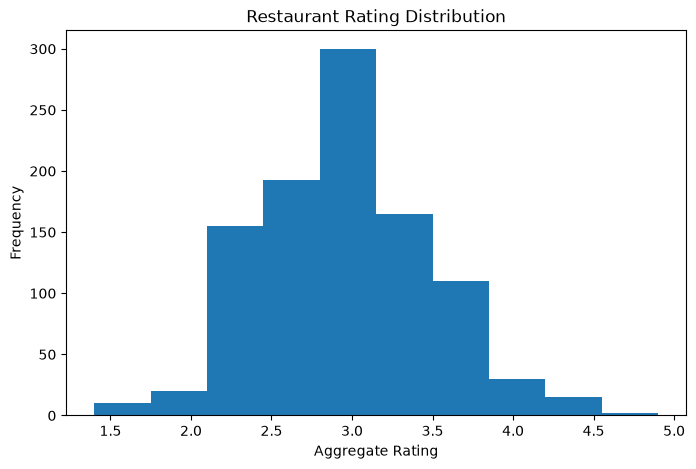

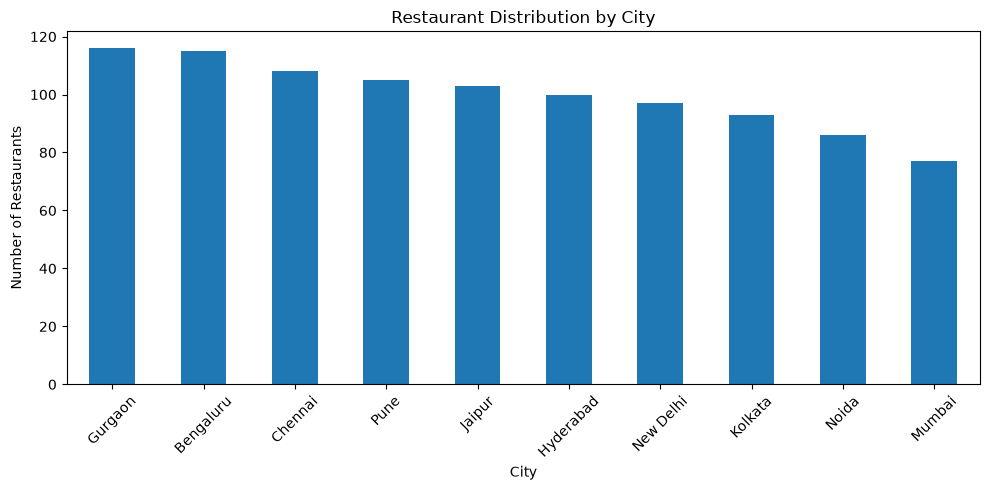

All visualizations generated successfully!


In [5]:
# STEP 5: DATA VISUALIZATION

# Cuisine distribution
plt.figure(figsize=(10, 5))
df["Cuisines"].value_counts().plot(kind="bar")
plt.title("Restaurant Distribution by Cuisine")
plt.xlabel("Cuisine")
plt.ylabel("Number of Restaurants")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Rating distribution
plt.figure(figsize=(8, 5))
df["Aggregate rating"].plot(kind="hist", bins=10)
plt.title("Restaurant Rating Distribution")
plt.xlabel("Aggregate Rating")
plt.ylabel("Frequency")
plt.show()

# City distribution
plt.figure(figsize=(10, 5))
df["City"].value_counts().plot(kind="bar")
plt.title("Restaurant Distribution by City")
plt.xlabel("City")
plt.ylabel("Number of Restaurants")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print("All visualizations generated successfully!")

In [6]:
# STEP 6: FEATURE EXTRACTION USING TF-IDF

df["Features"] = (
    df["City"] + " " +
    df["Cuisines"] + " " +
    df["Price range"].astype(str)
)

vectorizer = TfidfVectorizer()

feature_matrix = vectorizer.fit_transform(df["Features"])

print("TF-IDF feature extraction completed!")
print("Feature matrix shape:", feature_matrix.shape)

TF-IDF feature extraction completed!
Feature matrix shape: (1000, 23)


In [7]:
# STEP 7: COSINE SIMILARITY

similarity_matrix = cosine_similarity(feature_matrix)

print("Cosine similarity calculated successfully!")
print("Similarity matrix shape:", similarity_matrix.shape)

Cosine similarity calculated successfully!
Similarity matrix shape: (1000, 1000)


In [8]:
# STEP 8: RESTAURANT RECOMMENDATION FUNCTION

def recommend_restaurants(city=None, cuisine=None,
                          price_range=None, top_n=5):

    preferences = []

    if city:
        preferences.append(str(city).strip())

    if cuisine:
        preferences.append(str(cuisine).strip())

    if price_range is not None:
        preferences.append(str(price_range))

    if not preferences:
        print("Please enter at least one preference.")
        return pd.DataFrame()

    query = " ".join(preferences)

    query_vector = vectorizer.transform([query])

    scores = cosine_similarity(
        query_vector, feature_matrix
    ).flatten()

    results = df.copy()
    results["Similarity Score"] = scores

    if city:
        results = results[
            results["City"].str.lower() ==
            str(city).strip().lower()
        ]

    if cuisine:
        results = results[
            results["Cuisines"].str.lower() ==
            str(cuisine).strip().lower()
        ]

    if price_range is not None:
        results = results[
            results["Price range"] == price_range
        ]

    if results.empty:
        print("No matching restaurants found.")
        return pd.DataFrame()

    results["Rating Score"] = (
        results["Aggregate rating"].clip(0, 5) / 5
    )

    results["Vote Score"] = (
        np.log1p(results["Votes"]) /
        np.log1p(max(df["Votes"].max(), 1))
    )

    results["Recommendation Score"] = (
        0.45 * results["Similarity Score"] +
        0.40 * results["Rating Score"] +
        0.15 * results["Vote Score"]
    )

    results = results.sort_values(
        "Recommendation Score",
        ascending=False
    )

    columns = [
        "Restaurant ID",
        "City",
        "Cuisines",
        "Average Cost for two",
        "Price range",
        "Aggregate rating",
        "Votes",
        "Similarity Score",
        "Recommendation Score"
    ]

    return results[columns].head(top_n)

print("Recommendation function created successfully!")

Recommendation function created successfully!


In [9]:
# STEP 9: TEST RECOMMENDATION SYSTEM

recommendations = recommend_restaurants(
    city="New Delhi",
    cuisine="Cafe",
    price_range=2,
    top_n=5
)

print("TOP 5 RECOMMENDED RESTAURANTS")

display(recommendations)

TOP 5 RECOMMENDED RESTAURANTS


,Restaurant ID,City,Cuisines,Average Cost for two,Price range,Aggregate rating,Votes,Similarity Score,Recommendation Score
545,100546,New Delhi,Cafe,1000,2,3.1,994,1.0,0.830344
146,100147,New Delhi,Cafe,1200,2,3.2,441,1.0,0.822787
900,100901,New Delhi,Cafe,800,2,2.7,1269,1.0,0.803023
414,100415,New Delhi,Cafe,1000,2,2.3,930,1.0,0.765069
727,100728,New Delhi,Cafe,800,2,2.5,101,1.0,0.738673


In [10]:
# STEP 10: SAVE MODEL AND RESULTS

# Find the main project folder
if os.path.exists("../Dataset/zomato.csv"):
    project_dir = ".."
else:
    project_dir = "."

# Create required folders
for folder in ["Model", "Output", "Reports"]:
    os.makedirs(os.path.join(project_dir, folder), exist_ok=True)

# Save cleaned dataset
df.to_csv(
    os.path.join(project_dir, "Output", "cleaned_zomato.csv"),
    index=False
)

# Save recommendations
recommendations.to_csv(
    os.path.join(project_dir, "Output", "test_recommendations.csv"),
    index=False
)

# Save model files
joblib.dump(
    vectorizer,
    os.path.join(project_dir, "Model", "tfidf_vectorizer.pkl")
)

joblib.dump(
    similarity_matrix,
    os.path.join(project_dir, "Model", "similarity_matrix.pkl")
)

# Save charts
plt.figure(figsize=(10, 5))
df["Cuisines"].value_counts().plot(kind="bar")
plt.title("Restaurant Distribution by Cuisine")
plt.tight_layout()
plt.savefig(
    os.path.join(project_dir, "Reports", "cuisine_distribution.png")
)
plt.close()

plt.figure(figsize=(8, 5))
df["Aggregate rating"].plot(kind="hist", bins=10)
plt.title("Restaurant Rating Distribution")
plt.tight_layout()
plt.savefig(
    os.path.join(project_dir, "Reports", "rating_distribution.png")
)
plt.close()

plt.figure(figsize=(10, 5))
df["City"].value_counts().plot(kind="bar")
plt.title("Restaurant Distribution by City")
plt.tight_layout()
plt.savefig(
    os.path.join(project_dir, "Reports", "city_distribution.png")
)
plt.close()

print("All project files saved successfully!")

All project files saved successfully!


In [11]:
# STEP 11: PROJECT CONCLUSION

print("""
========================================
COGNIFYZ TECHNOLOGIES
MACHINE LEARNING TASK 2
RESTAURANT RECOMMENDATION SYSTEM
========================================

Project completed successfully!

Techniques used:
1. Data Cleaning and Preprocessing
2. Exploratory Data Analysis
3. TF-IDF Vectorization
4. Cosine Similarity
5. Restaurant Recommendation
6. Recommendation Ranking

The system recommends restaurants using
city, cuisine, price range, ratings and votes.

========================================
""")

display(recommendations)


COGNIFYZ TECHNOLOGIES
MACHINE LEARNING TASK 2
RESTAURANT RECOMMENDATION SYSTEM

Project completed successfully!

Techniques used:
1. Data Cleaning and Preprocessing
2. Exploratory Data Analysis
3. TF-IDF Vectorization
4. Cosine Similarity
5. Restaurant Recommendation
6. Recommendation Ranking

The system recommends restaurants using
city, cuisine, price range, ratings and votes.




,Restaurant ID,City,Cuisines,Average Cost for two,Price range,Aggregate rating,Votes,Similarity Score,Recommendation Score
545,100546,New Delhi,Cafe,1000,2,3.1,994,1.0,0.830344
146,100147,New Delhi,Cafe,1200,2,3.2,441,1.0,0.822787
900,100901,New Delhi,Cafe,800,2,2.7,1269,1.0,0.803023
414,100415,New Delhi,Cafe,1000,2,2.3,930,1.0,0.765069
727,100728,New Delhi,Cafe,800,2,2.5,101,1.0,0.738673
